# Taller de Análisis **Exploratorio** **de** **Datos** (**EDA**)
## Caso de estudio: comercio electrónico, clientes y operación

**Nombre:** Eliza yepes tapia

---

## Propósito del taller

Asumir el rol de un equipo de analítica que recibe datos reales de una empresa y debe comprenderlos antes de tomar decisiones.

No existe una única ruta de análisis ni una respuesta predeterminada. Se debe decidir qué investigar, qué variables utilizar, qué transformaciones realizar y cómo comunicar sus hallazgos.

**Regla de trabajo:** no se considera suficiente ejecutar código o producir gráficos. Cada decisión debe tener una justificación y cada resultado importante debe interpretarse en su contexto.

## Dataset seleccionado

**Brazilian E-Commerce Public Dataset by Olist**

Fuente: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

El conjunto contiene información anonimizada de aproximadamente 100.000 pedidos realizados entre 2016 y 2018. Los datos están distribuidos en archivos CSV relacionados entre sí.

### Archivos disponibles

| Archivo | Información general |
|---|---|
| `olist_orders_dataset.csv` | Pedidos, estados y fechas del proceso |
| `olist_order_items_dataset.csv` | Artículos, vendedores, precios y flete |
| `olist_customers_dataset.csv` | Identificadores y ubicación de clientes |
| `olist_products_dataset.csv` | Categorías y características de productos |
| `olist_sellers_dataset.csv` | Identificadores y ubicación de vendedores |
| `olist_order_payments_dataset.csv` | Formas y valores de pago |
| `olist_order_reviews_dataset.csv` | Calificaciones y comentarios |
| `olist_geolocation_dataset.csv` | Coordenadas asociadas a códigos postales |
| `product_category_name_translation.csv` | Traducción de categorías de productos |

**Importante:** no es obligatorio utilizar los nueve archivos. Selecciona los que necesitas para responder una pregunta de análisis. Antes de unir tablas, investiga qué representa cada fila y qué relación existe entre ellas.

# Fase 1. Comprensión del problema

## **1.1 Conocer el contexto**

1.**¿Qué tipo de organización o actividad económica  representa este conjunto de datos?**



 *Olist conecta pequeñas tiendas con grandes mercados en línea de Brasil*


---


2.**¿Qué procesos del negocio crees que pueden estudiarse con esta información?**

Se pueden estudiar los pedidos y sus entregas. Esta base de datos también tiene información sobre productos, pagos y clientes, pero en este trabajo quiero concentrarme en los pedidos


---

3.**¿Qué decisiones podría tomar una empresa a partir de un análisis de estos datos?**

Si encuentro muchos pedidos entregados tarde, la empresa podría investigar que esta pasando con las entregas y revisar como puede cumplir mejor las fechas estimadas.


---

4.**¿Qué información crees que hace falta para comprender completamente el negocio?**

Me gustaria saber quien transporto cada pedido y por que pudo haberse retrasado.


---

## **1.2 Conectar el análisis con una perspectiva profesional**

Piensa en tu formación, experiencia o área de interés.

1.**¿Qué aspecto del negocio te resulta más interesante investigar?**

Me da curiosidad saber si los pedidos llegan en el tiempo estimado, creo que es un pilar a considerar en la satisfaccion del cliente, y a mas clientes a gusto mas ventas


---
2.**¿Qué problema real de esa área podrías analizar con estos datos?**
si llegase a encontrar que algunos pedidos llegan despues de la fecha estimada, podria investigar la razon por la que esto sucede y si hay periodos en los que esto ocurre mas, por ejemplo diciembre y concluir que mejoras se podrian hacer


---
3.**¿Qué archivo podría contener información útil para investigarlo?**
El archivo de pedidos, porque contiene estados y fechas de los pedidos


---
4.**¿Qué variable o indicador les gustaría comprender?**

Quiero comparar la fecha estimada con la fecha real de entrega y calcular qué porcentaje de los pedidos entregados llegó tarde.


---


5.**¿Por qué el resultado de tu análisis sería útil para alguien que debe tomar decisiones?**
podría ayudar a la empresa a darse cuenta de si necesita revisar su proceso de entrega.

---
**Define una perspectiva inicial de análisis:**

Quiero mirar estos datos desde el lado del cliente. Cuando alguien compra por internet, espera que la empresa cumpla lo que le prometio. Me interesa entender que nos pueden contar los pedidos sobre esa experiencia y que aspectos debería revisar Olist para que sus clientes confíen en el servicio

In [3]:
# Escribe aquí las primeras ideas, hipótesis o preguntas que quieras investigar.


## **Fase 2**
# **Selección y conocimiento de los datos**

## *2.1 Selección de un único archivo*

1.**¿Qué pregunta de negocio quieres responder?**

Quiero saber si los pedidos llegaron en la fecha estimada.

---

2.**¿Qué archivo o archivos necesitan para responderla?**
Voy a usar:
 olist_orders_dataset.csv

 ---

3.**¿Por qué seleccionaron esos archivos y descartaron los demás?**

Elegi este porque contiene información de los pedidos y las entregas y creo que eso responde a mi pregunta de negocio.

Descarte los otros porque inicialmente no responden la pregunta y el tema de mi interes

Aunque pensandolo bien, mi interes es el cliente y su satisfaccion por eso tambien me gustaria investigar las reseñas.


---
4.**¿Qué representa una fila en cada archivo seleccionado?**

Segun la guia, cada fila de este archivo representa un pedido. Cuando abra el archivo, revisare la columna order_id para comprobarlo.

---

5.**¿Cuál podría ser la llave o identificador que permita relacionar los archivos?**

Si quisiera unir los pedidos con los artículos, buscaría la columna order_id en los dos archivos. Por ahora solo voy a usar el archivo de pedidos, así que no necesito unirlos

---


6.**¿Qué riesgos existen al unir tablas que tienen diferentes niveles de detalle?**

Un pedido puede tener varios artículos. Si junto esos archivos, el mismo pedido podría aparecer varias veces. Revisaría cuántos pedidos únicos hay para no contarlos de más.


**Nombre del único archivo seleccionado y justificación:**


In [4]:
# Escribe aquí el código para importar las librerías que consideres necesarias.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.2.3
NumPy: 2.4.6


In [7]:
from google.colab import files

archivos = files.upload()
nombre_archivo = next(iter(archivos))
df_pedidos = pd.read_csv(nombre_archivo)

Saving olist_orders_dataset.csv to olist_orders_dataset.csv


In [8]:
# Escribe aquí el código para identificar los objetos cargados y sus dimensiones.
print("Objeto cargado: df_pedidos")
df_pedidos.info()

print("Dimensiones (filas, columnas):", df_pedidos.shape)

Objeto cargado: df_pedidos
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
Dimensiones (filas, columnas): (99441, 8)


## 2.2 Reconocimiento de la estructura

Explora los datos antes de modificarlos.

1.**¿Cuántas filas y columnas tiene cada DataFrame?**
Tiene 99.441 filas y 8 columnas

---

2.**¿Qué representa cada columna?**

1.id de orden.

2.id del cliente

3.estado de la orden

4.fecha de compra

5.fecha en que se aprovo el pedido

6.fecha en que se entrego al transportador

7.fecha en que llego al cliente

8.fecha estimada de entrega

---

3.**¿Qué tipos de datos identifica Python?**

python identifica las 8 columnas como objet (texto)
aunque 5 columnas deberian ir en formato fecha.

---

4.**¿Qué variables son numéricas, categóricas, temporales o identificadores?**

no hay columnas numericas

order_status es categorica

las columnas con date o time son temporales

order y customer id son identificadores

---

5.**¿Qué variables parecen relevantes para la pregunta que planteaste?**

me parecen relevantes order_estimated_delivery_date,

order_delivered_customer_date y  order_status,

---


6.**¿Hay variables cuyo significado no sea evidente? ¿Cómo podrías investigarlo?**

---
7.**¿Qué observaciones iniciales te generan curiosidad?**

Vi que algunas fechas tienen valores vacíos y que Python todavía interpreta todas las columnas como texto.

**Registro de observaciones:**


In [9]:
# Escribe aquí el código necesario para inspeccionar la estructura de los datos.
print("Primeras filas del archivo:")
display(df_pedidos.head(30))



Primeras filas del archivo:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [10]:
print("Descripción:")
display(df_pedidos.describe(include="all"))

Descripción:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [11]:
# Escribe aquí el código para explorar registros y valores de las variables.
columnas = [
    "order_status",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

display(df_pedidos[columnas].sample(10, random_state=1))

print("Cantidad de pedidos por estado:")
print(df_pedidos["order_status"].value_counts(dropna=False))

,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
90678,delivered,2017-05-19 17:07:52,2017-06-08 18:07:41,2017-06-26 00:00:00
53288,delivered,2018-04-22 15:04:45,2018-04-27 19:06:55,2018-05-22 00:00:00
23486,delivered,2018-08-12 20:35:19,2018-08-17 19:21:46,2018-08-24 00:00:00
50028,delivered,2017-03-11 20:44:31,2017-03-23 15:05:56,2017-04-03 00:00:00
60525,delivered,2018-03-01 10:44:44,2018-03-05 18:16:59,2018-03-13 00:00:00
83885,delivered,2018-02-07 23:55:04,2018-02-22 21:38:54,2018-03-14 00:00:00
542,delivered,2018-08-05 11:05:53,2018-08-14 18:06:37,2018-08-15 00:00:00
78310,shipped,2017-06-18 00:27:16,NaN,2017-07-05 00:00:00
13580,delivered,2017-11-03 09:26:13,2017-11-13 22:32:31,2017-12-04 00:00:00
98420,delivered,2017-09-14 00:28:58,2017-09-28 21:32:51,2017-10-04 00:00:00


Cantidad de pedidos por estado:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64



# Apartado de apoyo. ¿Cómo unir tablas en Pandas?

Aunque el EDA principal se desarrolla sobre un único archivo, en un proyecto real puede ser necesario combinar información que está distribuida en varias tablas.

En Olist, por ejemplo, los pedidos y los datos de clientes se encuentran en archivos diferentes. Para analizarlos conjuntamente, se necesita identificar una columna que exista en ambas tablas y represente la misma entidad.

## Conceptos que debes comprender

- **Llave:** columna que permite relacionar registros entre tablas. Por ejemplo, `customer_id`.
- **Tabla izquierda (`left`):** DataFrame que se coloca primero en `merge`.
- **Tabla derecha (`right`):** DataFrame que se incorpora.
- **Tipo de unión (`how`):** define qué registros se conservan.

| Tipo | ¿Qué conserva? |
|---|---|
| `inner` | Solo las filas cuya llave aparece en ambas tablas. |
| `left` | Todas las filas de la tabla izquierda y las coincidencias de la derecha. |
| `right` | Todas las filas de la tabla derecha y las coincidencias de la izquierda. |
| `outer` | Todas las filas de ambas tablas; donde no hay coincidencia aparecen valores faltantes. |

## Estructura general

La función de Pandas utilizada es `merge()`:

```python
df_resultado = pd.merge(
    df_izquierdo,
    df_derecho,
    on="columna_llave",
    how="left"
)
```

Si las columnas que relacionan las tablas tienen nombres diferentes, se pueden utilizar `left_on` y `right_on`:

```python
df_resultado = pd.merge(
    df_izquierdo,
    df_derecho,
    left_on="id_tabla_1",
    right_on="id_tabla_2",
    how="inner"
)
```

## Antes de unir tablas, analiza

1. ¿Qué representa una fila en cada DataFrame?
2. ¿Cuál es la llave que relaciona las tablas?
3. ¿La llave es única en una tabla, en ambas o en ninguna?
4. ¿La relación es uno a uno, uno a muchos o muchos a muchos?
5. ¿Qué tipo de unión responde mejor a la pregunta de análisis?
6. ¿La unión puede duplicar registros? ¿Cómo lo comprobarías?
7. ¿Cuántas filas había antes y cuántas después de unir las tablas?

**Advertencia:** una unión técnicamente correcta puede producir resultados incorrectos si no se comprende el nivel de detalle de cada tabla. Por ejemplo, un pedido puede tener varios artículos; al unir pedidos con artículos, el pedido aparecerá en varias filas. Esto no necesariamente es un error: depende de qué representa cada fila en el resultado.

## Ejercicio de comprensión (no hace parte obligatoria del EDA)

Imagina que tienes una tabla de pedidos y otra de clientes.

- ¿Qué columna podría relacionarlas?
- Si quieres conservar todos los pedidos, incluso aquellos que no tengan coincidencia en la tabla de clientes, ¿qué tipo de unión elegirías?
- ¿Qué podría ocurrir si el identificador de cliente aparece varias veces en la tabla de clientes?
- ¿Qué validaciones realizarías después de la unión?

**Explica tus respuestas:**


In [12]:

# Espacio opcional para practicar merge() con dos DataFrames.
# Carga los archivos de pedidos y clientes solo si deseas realizar el ejercicio.
# Escribe aquí tu código de unión y las validaciones posteriores.
#Por ahora no voy a unir tablas porque mi pregunta se puede explorar con el archivo de pedidos.


# Fase 3. Calidad y confiabilidad de los datos

Antes de analizar el comportamiento del negocio, evalúa si los datos son suficientemente confiables.

## 3.1 Diagnóstico

1. ¿Existen valores faltantes? ¿En qué variables se concentran?
2. ¿Qué proporción representan los valores faltantes?
3. ¿Existen registros duplicados? ¿Son duplicados exactos o podrían representar eventos distintos?
4. ¿Los tipos de datos corresponden con el significado de las variables?
5. ¿Existen valores que parecen imposibles o poco razonables?
6. ¿Hay categorías escritas de diferentes maneras que podrían representar lo mismo?
7. ¿Los identificadores cumplen alguna condición de unicidad?
8. ¿Qué otros problemas de calidad pueden afectar sus resultados?

**¿Cuál de los problemas encontrados consideras más importante y por qué?**



In [13]:
# Escribe aquí el código para investigar los valores faltantes.
resumen = pd.DataFrame({
    "valores_faltantes": df_pedidos.isna().sum(),
    "porcentaje_faltante": (df_pedidos.isna().mean() * 100).round(2)
})

display(resumen)

,valores_faltantes,porcentaje_faltante
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00


In [14]:
# Escribe aquí el código para investigar duplicados.
print("Filas duplicadas completas:", df_pedidos.duplicated().sum())
print("order_id repetidos:", df_pedidos["order_id"].duplicated().sum())
print("customer_id repetidos:", df_pedidos["customer_id"].duplicated().sum())

Filas duplicadas completas: 0
order_id repetidos: 0
customer_id repetidos: 0


In [15]:
# Escribe aquí el código para revisar tipos de datos, categorías y posibles inconsistencias.
print("Tipos de datos reconocidos por Python:")
display(df_pedidos.dtypes.to_frame(name="tipo"))

print("Cantidad de pedidos por estado:")
display(df_pedidos["order_status"].value_counts(dropna=False).to_frame(name="cantidad"))

print("Nombres exactos de los estados:")
print(sorted(df_pedidos["order_status"].dropna().unique()))

Tipos de datos reconocidos por Python:


,tipo
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,object
order_approved_at,object
order_delivered_carrier_date,object
order_delivered_customer_date,object
order_estimated_delivery_date,object


Cantidad de pedidos por estado:


,cantidad
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


Nombres exactos de los estados:
['approved', 'canceled', 'created', 'delivered', 'invoiced', 'processing', 'shipped', 'unavailable']


In [16]:
# Escribe aquí el código para investigar los valores sospechosos que hayan identificado.
columnas_fecha = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

fechas = df_pedidos[columnas_fecha].apply(
    lambda columna: pd.to_datetime(columna, errors="coerce")
)

fechas_invalidas = df_pedidos[columnas_fecha].notna() & fechas.isna()

print("Fechas no interpretables por columna:")
display(fechas_invalidas.sum().to_frame(name="cantidad"))

Fechas no interpretables por columna:


,cantidad
order_purchase_timestamp,0
order_approved_at,0
order_delivered_carrier_date,0
order_delivered_customer_date,0
order_estimated_delivery_date,0


In [17]:
comparaciones = {
    "Aprobación anterior a la compra":
        fechas["order_approved_at"] < fechas["order_purchase_timestamp"],

    "Entrega al transportador anterior a la compra":
        fechas["order_delivered_carrier_date"] < fechas["order_purchase_timestamp"],

    "Entrega al cliente anterior a la fecha del transportador":
        fechas["order_delivered_customer_date"] < fechas["order_delivered_carrier_date"]
}

for nombre, resultado in comparaciones.items():
    print(nombre, ":", resultado.sum())

Aprobación anterior a la compra : 0
Entrega al transportador anterior a la compra : 166
Entrega al cliente anterior a la fecha del transportador : 23


In [18]:
columnas = [
    "order_id",
    "order_status",
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

casos_1 = comparaciones["Entrega al transportador anterior a la compra"]
casos_2 = comparaciones["Entrega al cliente anterior a la fecha del transportador"]

print("Ejemplos: transportador antes de compra")
display(df_pedidos.loc[casos_1, columnas].head(10))

print("Ejemplos: cliente antes de transportador")
display(df_pedidos.loc[casos_2, columnas].head(10))

Ejemplos: transportador antes de compra


,order_id,order_status,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date
615,b9afddbdcfadc9a87b41a83271c3e888,delivered,2018-08-16 13:50:48,2018-08-16 13:27:00,2018-08-24 14:58:37
1111,ad133696906f6a78826daa0911b7daec,delivered,2018-06-15 15:41:22,2018-06-15 14:52:00,2018-06-22 18:09:37
1329,74e033208dc13a7b8127eb8e73d09b76,delivered,2018-05-02 10:48:44,2018-05-02 09:49:00,2018-05-07 23:06:36
1372,a6b58794fd2ba533359a76c08df576e3,delivered,2018-05-14 15:18:23,2018-05-14 13:46:00,2018-05-19 19:33:32
1864,5792e0b1c8c8a2bf53af468c9a422c88,delivered,2018-07-26 13:25:14,2018-07-26 12:42:00,2018-07-30 14:45:02
2760,c3eb293fd154223498b6551a728203e8,delivered,2018-07-19 14:06:04,2018-07-19 13:49:00,2018-07-24 19:35:36
3473,b0c2a7d04b165525254254a728c50a4e,delivered,2018-06-07 13:28:30,2018-06-07 13:22:00,2018-06-21 17:36:43
3661,2033a4586b5bec3229ebc1675a8ae092,delivered,2018-06-12 10:10:25,2018-06-12 10:09:00,2018-06-19 14:08:27
4114,08adcddad19d3acf37d1fa01cb9ded1e,delivered,2018-06-27 11:16:44,2018-06-27 10:57:00,2018-06-29 17:39:53
4159,dee6298ce7d1fb2645141ef9972157aa,shipped,2018-04-30 14:06:12,2018-04-30 12:59:00,NaN


Ejemplos: cliente antes de transportador


,order_id,order_status,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-20 11:20:52,2017-07-28 16:57:58,2017-07-25 19:32:56
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-02 20:58:43,2017-07-07 17:22:41,2017-07-06 14:27:51
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-16 12:35:34,2017-07-20 19:22:02,2017-07-19 14:13:28
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-07-20 20:58:05,2017-08-01 18:23:30,2017-07-26 18:09:10
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-18 11:48:20,2017-07-20 23:03:42,2017-07-20 18:52:41
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-08 15:36:50,2016-10-26 11:41:53,2016-10-25 17:51:46
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-14 20:17:04,2017-06-27 14:51:54,2017-06-26 15:45:35
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-07 21:35:22,2017-08-10 18:28:56,2017-08-10 18:05:38
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-07-26 11:46:34,2017-08-01 18:17:47,2017-07-31 17:49:56
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-07-30 19:32:23,2017-08-09 18:18:43,2017-08-01 21:13:01


Al revisar los datos, vi algunos valores vacios en las fechas y no encontre filas repetidas. Tambien encontre fechas fuera de orden en algunos pedidos.

## 3.2 Decisiones de tratamiento

No todos los problemas deben resolverse de la misma manera.

Para cada problema identificado, responde:

1.**¿Qué evidencia demuestra que existe un problema?**

faltan 160 fechas de aprobado

 1.783 fechas de entrega al transportador

 y 2.965 fechas de entrega al cliente

 Ademas al comparar las fechas encontre 166 pedidos donde la fecha del transportados aparece antes que la compra y 23 donde la entrega al cliente aparece antes que la del transportador

 ---

2.**¿Qué alternativas de tratamiento consideran?**

con las fechas podria convertirlas en formato de fecha  para analizarlas  y para las fechas que aparecen fuera de orden, puedo revisarlas y corregirlas despues si es posible.

---

3.**¿Qué información se perdería si eliminan registros?**
Si elimino esos registros, perderia información de pedidos completos,  También podria cambiar la proporción de pedidos entregados y de otros estados. Por eso prefiero conservarlos y dejar fuera de cada cálculo solo los pedidos que no tengan las fechas necesaria

---

4.**¿Qué consecuencias tendría conservar los valores sin modificarlos?**
Si conservo esos valores, mantengo la información original y evito inventar fechas. Pero no podre calcular los tiempos de entrega de los pedidos que no tienen fecha

con las fechas fuera de orden podrían dar resultados engañosos.
 Por eso conservaré los datos originales y dejaré fuera de cada cálculo solo los registros que no sirvan para esa comparación

 ---

5.**¿Qué decisión tomarán y cómo justificarían esa decisión ante un equipo de negocio?**

Voy a conservar el archivo original y En una copia convertire las columnas de fechas para poder compararlas, pero no completare los espacios vacíos porque no sé cuáles fueron las fechas reales.

 Para medir la puntualidad usarec los pedidos entregados que tengan fecha real y estimada.

 También dejare aparte los 23 casos en que la entrega al cliente aparece antes que la del transportador, porque no quiero basar el resultado en fechas insiertas y no me las puedo inventar. Así que mantengo los datos y no invento información.

In [19]:
df_limpio = df_pedidos.copy()

for columna in columnas_fecha:
    df_limpio[columna] = pd.to_datetime(
        df_limpio[columna],
        errors="coerce"
    )

cliente_antes_transportador = (
    df_limpio["order_delivered_customer_date"]
    < df_limpio["order_delivered_carrier_date"]
)

df_analisis = df_limpio[
    (df_limpio["order_status"] == "delivered")
    & df_limpio["order_delivered_customer_date"].notna()
    & df_limpio["order_estimated_delivery_date"].notna()
    & ~cliente_antes_transportador
].copy()

In [20]:
# Escribe aquí el código para verificar qué cambió después del tratamiento.
print("Tamaño del archivo original:", df_pedidos.shape)
print("Tamaño de la copia con fechas preparadas:", df_limpio.shape)
print("Pedidos para analizar:", len(df_analisis))

print("Tipos de las fechas después del cambio:")
display(df_limpio[columnas_fecha].dtypes.to_frame(name="tipo"))

print("Fechas vacías antes y después:")
display(pd.DataFrame({
    "antes": df_pedidos[columnas_fecha].isna().sum(),
    "despues": df_limpio[columnas_fecha].isna().sum()
}))

Tamaño del archivo original: (99441, 8)
Tamaño de la copia con fechas preparadas: (99441, 8)
Pedidos para analizar: 96447
Tipos de las fechas después del cambio:


,tipo
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


Fechas vacías antes y después:


,antes,despues
order_purchase_timestamp,0,0
order_approved_at,160,160
order_delivered_carrier_date,1783,1783
order_delivered_customer_date,2965,2965
order_estimated_delivery_date,0,0


In [23]:
entregado = df_limpio["order_status"] == "delivered"
sin_fecha_real = df_limpio["order_delivered_customer_date"].isna()

cliente_antes_transportador = (
    df_limpio["order_delivered_customer_date"]
    < df_limpio["order_delivered_carrier_date"]
)

print("Pedidos entregados:", entregado.sum())
print("Entregados sin fecha real:", (entregado & sin_fecha_real).sum())
print(
    "Fechas cliente anteriores al transportador:",
    int(cliente_antes_transportador.sum())
)
print("Pedidos que quedaron para analizar:", len(df_analisis))

Pedidos entregados: 96478
Entregados sin fecha real: 8
Fechas cliente anteriores al transportador: 23
Pedidos que quedaron para analizar: 96447


In [24]:
df_analisis["diferencia_dias"] = (
    df_analisis["order_delivered_customer_date"]
    - df_analisis["order_estimated_delivery_date"]
).dt.days

df_analisis["diferencia_dias"].describe()

,diferencia_dias
count,96447.000000
mean,-11.872884
std,10.179730
min,-147.000000
25%,-17.000000
50%,-12.000000
75%,-7.000000
max,188.000000


In [25]:
d = df_analisis["diferencia_dias"]

cantidades = pd.Series({
    "Antes de la fecha estimada": (d < 0).sum(),
    "En la fecha estimada": (d == 0).sum(),
    "Despues de la fecha estimada": (d > 0).sum()
})

resumen_entregas = pd.DataFrame({
    "pedidos": cantidades,
    "porcentaje": (cantidades / len(d) * 100).round(2)
})

display(resumen_entregas)

,pedidos,porcentaje
Antes de la fecha estimada,88621,91.89
En la fecha estimada,1292,1.34
Despues de la fecha estimada,6534,6.77


In [26]:
d = df_analisis["diferencia_dias"]

print("Media:", d.mean())
print("Mediana:", d.median())
print("Moda:", d.mode().tolist())

Media: -11.872883552624758
Mediana: -12.0
Moda: [-14]


In [27]:
d = df_analisis["diferencia_dias"]
indices_extremos = [d.idxmin(), d.idxmax()]

display(df_analisis.loc[
    indices_extremos,
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "diferencia_dias"
    ]
])

,order_id,order_status,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,diferencia_dias
40094,0607f0efea4b566f1eb8f7d3c2397320,delivered,2018-03-06 09:47:07,2018-03-07 21:33:39,2018-03-09 23:36:47,2018-08-03,-147
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,2018-02-23 14:57:35,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15,188


In [28]:
df_analisis["mes_compra"] = (
    df_analisis["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

df_analisis["llego_tarde"] = df_analisis["diferencia_dias"] > 0

resumen_mensual = df_analisis.groupby("mes_compra").agg(
    pedidos=("order_id", "count"),
    porcentaje_tarde=("llego_tarde", lambda valores: valores.mean() * 100),
    diferencia_mediana=("diferencia_dias", "median")
).round(2)

display(resumen_mensual)

,pedidos,porcentaje_tarde,diferencia_mediana
mes_compra,,,
2016-09,1,100.00,36.0
2016-10,261,0.77,-39.0
2016-12,1,0.00,-22.0
2017-01,749,2.94,-29.0
2017-02,1651,2.97,-20.0
2017-03,2545,4.56,-14.0
2017-04,2303,6.56,-14.0
2017-05,3544,2.99,-14.0
2017-06,3134,3.03,-13.0


la mayoria llego antes de la fecha estimada.
Un 6,77 % llego despues. Esto muestra que la mayoria cumplio la fecha o llego antes, aunque todavia falta investigar si los retrasos cambian según el mes.

---
**Actualizacion**
Cuando compare los pedidos por mes, vi que el porcentaje de retrasos cambiaba. De los meses que aparecen, marzo de 2018 tuvo el porcentaje mas alto de pedidos tardios


# Fase 4. Comprensión estadística y análisis univariado

Ahora investiguen las variables individualmente.

## 4.1 Variables numéricas

1.**¿Qué medidas estadísticas permiten comprender mejor estas variables?**

Para entender la variable diferencia_dias revise la media y la mediana para saber cuantos dias antes o despues de la fecha estimada suelen llegar los pedidos y me di cuenta que llegaron unos 12 dias antes de lo esperado. Tambien encontre algunos casos muy distintos: teniendo en cuenta los extremos, uno llego 147 dias antes y otro 188 dias despues.

---
2.**¿Qué diferencias encuentran entre media, mediana y moda?**
La media y la mediana son casi iguales, cerca de 12 dias antes de la fecha estimada. El valor que mas se repitio fue 14 dias antes. En general, las tres medidas muestran que los pedidos solian llegar antes de lo previsto.

---


3.**¿Qué variables presentan mayor dispersión?**

En este archivo casi todo son fechas, estados o codigos. La unica cantidad que calcule fue la diferencia en dias. No todos los pedidos se comportaron igual: algunos llegaron 147 dias antes y otros 188 dias despues de lo estimado. Por eso digo que hay bastante variacion.

---

4.**¿Qué tan concentrados o dispersos están sus valores?**
eatan relativamente concentrados

---

5.**¿Existen observaciones extremas?**

Si, encontre valores extremos algunos pedidos aparecen 147 dias antes de la fecha estimada y otros 188 dias despues.

---


6.**¿Esos valores extremos son errores, casos especiales o comportamientos reales?**
basandome solo en archivo de pedidos no pude confirmar si son errores, casos especiales o comportamientos reales, tendria que traer mas archivos y analizarlos

---

7.**¿Qué visualización permitiría comprender mejor cada distribución?**

para diferencia_dias usaria un histograma para ver donde se agrupan los pedidos y un diagrama de caja para notar los valores muy alejados, como -147 y 188 dias.

---

8.**¿Qué información aporta la visualización que no sea evidente en una tabla?**

La tabla me da los numeros exactos, pero el grafico me permite ver rapido donde se concentran los pedidos y si hay valores muy alejados, como −147 y 188 dias. Asi puedo notar el patron sin revisar cada fila.


In [29]:
# Escribe aquí el código para desarrollar el análisis estadístico.
#LO RESPONDI UNAS CELDAS ATRAS

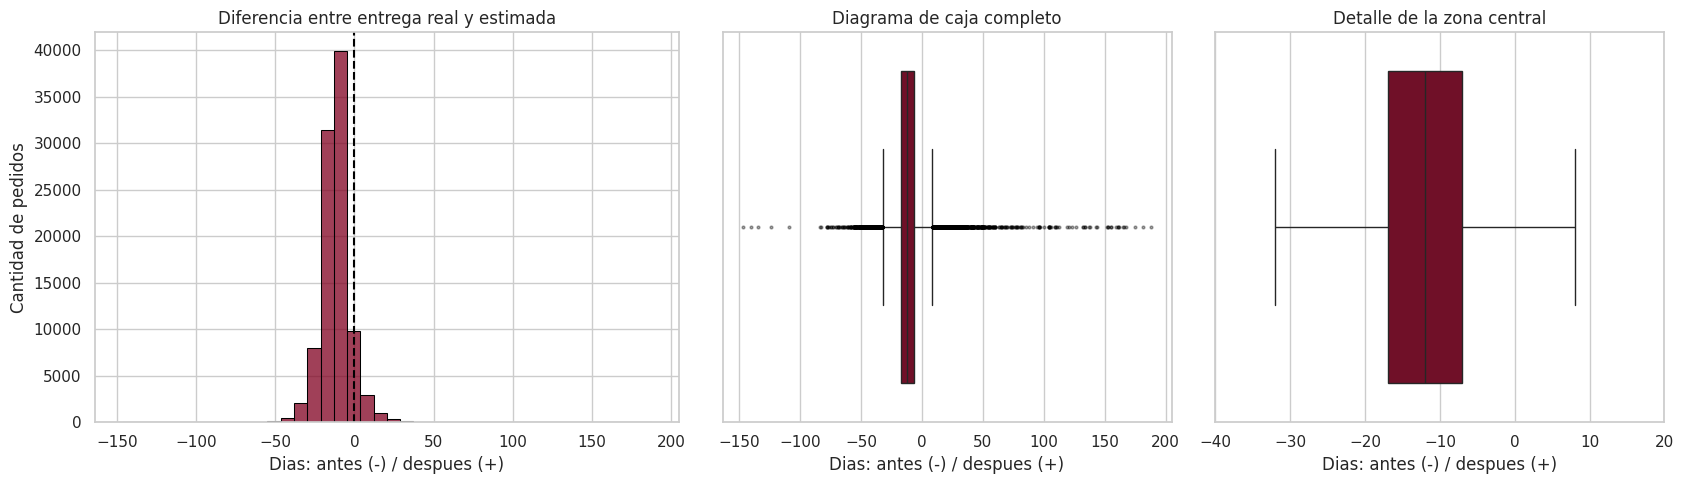

In [33]:
sns.set_theme(style="whitegrid")

fig, ejes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    gridspec_kw={"width_ratios": [1.3, 1, 1]}
)

# Histograma: muestra el rango completo
sns.histplot(
    data=df_analisis,
    x="diferencia_dias",
    bins=40,
    color="#800020",
    edgecolor="black",
    ax=ejes[0]
)
ejes[0].axvline(0, color="black", linestyle="--")
ejes[0].set_title("Diferencia entre entrega real y estimada")
ejes[0].set_xlabel("Dias: antes (-) / despues (+)")
ejes[0].set_ylabel("Cantidad de pedidos")

# Diagrama completo: muestra los puntos extremos
sns.boxplot(
    x=df_analisis["diferencia_dias"],
    color="#800020",
    showfliers=True,
    flierprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 2,
        "alpha": 0.35
    },
    ax=ejes[1]
)
ejes[1].set_title("Diagrama de caja completo")
ejes[1].set_xlabel("Dias: antes (-) / despues (+)")

# Detalle central: permite ver mejor la caja
sns.boxplot(
    x=df_analisis["diferencia_dias"],
    color="#800020",
    showfliers=False,
    ax=ejes[2]
)
ejes[2].set_xlim(-40, 20)
ejes[2].set_title("Detalle de la zona central")
ejes[2].set_xlabel("Dias: antes (-) / despues (+)")

plt.tight_layout()
plt.show()

## 4.2 Variables categóricas

1.**¿Cuáles son las categorías más frecuentes?**

Las categorias mas frecuentes son delivered (96.478 pedidos), shipped (1.107), canceled (625) y unavailable (609). Las demas aparecen mucho menos.

---

2.**¿Existen categorías poco representadas?**
Si. created aparece 5 veces y approved solo 2

---

3.**¿La categoría más frecuente es necesariamente la más importante para el negocio?**


No necesariamente. delivered es el estado mas comun, pero canceled y unavailable, aunque aparecen menos, tambien pueden ser importantes porque representan pedidos que no se completaron. La importancia depende de lo que la empresa quiera mejorar, no solo de cuantas veces aparece una categoria.

---

4.**¿Qué diferencias existen entre contar registros, pedidos, clientes y unidades?**
 ¿Qué diferencias existen entre contar registros, pedidos, clientes y unidades?

 ---

5.**¿Qué visualización facilita la comparación entre categorías?**

Un grafico de barras horizontale permite comparar la cantidad de pedidos

---

6.**¿Qué categorías merecen una investigación adicional?**
Me interesaria revisar canceled (625) y unavailable (609), porque esos pedidos no aparecen como entregados.

**¿Qué descubrimiento obtuviste al analizar las variables categóricas?**
Lo que mas me llamo la atencion es que casi todos los pedidos aparecen como delivered (96.478). En cambio, canceled y unavailable suman mas de mil pedidos
**Actualizacion**
Con el archivo que elegi podemos ver cuantos pedidos quedaron cancelados o no disponibles, pero no la razon exacta, sus columnas registran estados y fechas, no un campo de “motivo de cancelación”.

En la descripción del de Olist muestra que hay otros datos, como productos, pagos y reseñas y ahora creo que debi cruzarlos, me deje llevar por la idea de que con un solo archivo podria descubrir mi idea inicial que era investigar si los pedidos llegaban en la fecha estimada o se retrasaban.
y tambien para no hacer el archivo muy grande, queria algo mas simple pero ahora tengo otra duda de negocio como por qué se cancelaron algunos pedidos

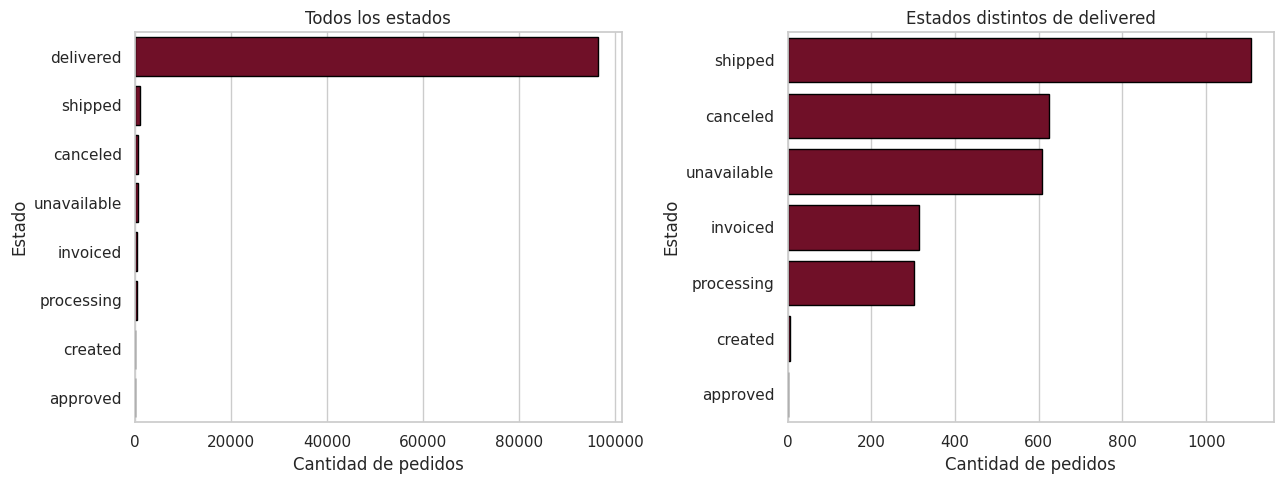

In [35]:
# Escribe aquí el código para analizar las variables categóricas y construir sus visualizaciones.
conteo_estados = df_pedidos["order_status"].value_counts()
otros_estados = conteo_estados.drop("delivered")

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    x=conteo_estados.values,
    y=conteo_estados.index,
    color="#800020",
    edgecolor="black",
    ax=ejes[0]
)
ejes[0].set_title("Todos los estados")
ejes[0].set_xlabel("Cantidad de pedidos")
ejes[0].set_ylabel("Estado")

sns.barplot(
    x=otros_estados.values,
    y=otros_estados.index,
    color="#800020",
    edgecolor="black",
    ax=ejes[1]
)
ejes[1].set_title("Estados distintos de delivered")
ejes[1].set_xlabel("Cantidad de pedidos")
ejes[1].set_ylabel("Estado")

plt.tight_layout()
plt.show()

# Fase 5. Relaciones entre variables

Un análisis exploratorio no debe limitarse a describir columnas por separado. Busca relaciones que permitan comprender mejor el fenómeno.

## 5.1 Formulación de hipótesis

Plantea al menos tres hipótesis que puedan investigar con los datos seleccionados.

Para cada hipótesis:

- ¿Qué variables necesitas?
- ¿Qué relación esperas encontrar?
- ¿Por qué consideras que podría existir esa relación?
- ¿Qué resultado podría contradecir su hipótesis?

**Hipótesis 1:**
los retrasos cambian segun el mes de compra
- Variables: mes de compra y diferencia entre la fecha real y la estimada.
- Qué espero encontrar: que el porcentaje de pedidos tardios sea distinto entre algunos meses.
- Por que podria pasar: puede haber meses con más pedidos que otros.
- Que la contradice: que, al comparar los meses, el porcentaje de retrasos sea parecido.

---


**Hipótesis 2:**
los pedidos que tardan más en aprobarse tienden a retrasarse más
- Variables: fecha de compra, fecha de aprobación y diferencia entre la entrega real y la estimada.
- Que espero encontrar: que los pedidos con más tiempo entre compra y aprobación tiendan a tener más días de retraso.
- Por que podria pasar: una aprobación mss lenta podria dejar menos tiempo para preparar y enviar el pedido.
- Que la contradice: que el tiempo de aprobación no tenga relación con los días de retraso.

---

**Hipótesis 3:**

los pedidos que tardan más en llegar al transportador tienden a retrasarse más
- Variables: fecha de compra, fecha de entrega al transportador y diferencia entre la entrega real y la estimada.
- Que espero encontrar: que los pedidos que tardan más en llegar al transportador tengan más retrasos.
- Por qué podría pasar: si el envío empieza tarde, podría quedar menos tiempo para entregar el pedido.
- Que la contradice: que los pedidos con mas espera hasta el transportador no tengan mas retrasos.

In [37]:
# Escribe aquí el código para investigar las hipótesis planteadas.
# Hipotesis 2: tiempo entre compra y aprobacion vs. retraso
datos_aprobacion = df_analisis.dropna(
    subset=["order_approved_at"]
).copy()

datos_aprobacion["horas_hasta_aprobacion"] = (
    datos_aprobacion["order_approved_at"]
    - datos_aprobacion["order_purchase_timestamp"]
).dt.total_seconds() / 3600

correlacion_aprobacion = datos_aprobacion[
    "horas_hasta_aprobacion"
].corr(datos_aprobacion["diferencia_dias"], method="spearman")

print("Relacion entre aprobacion y retraso:", round(correlacion_aprobacion, 3))


# Hipotesis 3: tiempo hasta el transportador vs. retraso
datos_transportador = df_analisis[
    df_analisis["order_delivered_carrier_date"].notna()
    & (
        df_analisis["order_delivered_carrier_date"]
        >= df_analisis["order_purchase_timestamp"]
    )
].copy()

datos_transportador["dias_hasta_transportador"] = (
    datos_transportador["order_delivered_carrier_date"]
    - datos_transportador["order_purchase_timestamp"]
).dt.total_seconds() / 86400

correlacion_transportador = datos_transportador[
    "dias_hasta_transportador"
].corr(datos_transportador["diferencia_dias"], method="spearman")

print("Relacion entre espera del transportador y retraso:",
      round(correlacion_transportador, 3))

Relacion entre aprobacion y retraso: 0.058
Relacion entre espera del transportador y retraso: 0.184


Al mirar los resultados, vi que el tiempo de aprobacion casi no se relaciona con los retrasos. La espera del transportador tiene un poquito mas de relacion, pero sigue siendo baja. Con esto no puedo decir que esperar mas sea la causa de que un pedido llegue tarde.

# Fase 6. Análisis temporal, segmentación o análisis geográfico

No todos los análisis necesitan abordar las tres perspectivas. Seleccionen las que tengan sentido para su pregunta de negocio y para las variables disponibles.

## 6.1 Análisis temporal

1.**¿Qué variables contienen fechas?**
el archivo tiene fechas de compra, aprobación, entrega al transportador, entrega al cliente y fecha estimada de entrega

---

2.**¿Qué periodos pueden analizarse**
Los pedidos se pueden comparar por mes de compra.

---
3.**¿Cómo cambia el comportamiento a través del tiempo?**
En los resultados que se ven, el porcentaje de retrasos cambia entre meses.

---
4.**¿Existen temporadas o periodos con comportamientos diferentes?**
si. Algunos meses tienen porcentajes de retraso más altos que otros. Hay que tener cuidado con los meses que tienen muy pocos pedidos: un porcentaje alto basado en un solo pedido no es comparable con uno basado en miles.

---

5.**¿Qué eventos o condiciones podrían explicar esos cambios?**

podrian explicar temporadas con mas compras,menos compras el volumen de pedidos

---

6.**¿Qué limitaciones tiene la información temporal disponible?**
El archivo muestra fechas y estados, pero no explica por que se retraso un pedido. Ademas, algunos pedidos no tienen fecha real de entrega y otros tenian fechas fuera del orden esperado, por lo que no se incluyeron en la comparación.

---


**Pregunta temporal que desean investigar:**
Como cambia el porcentaje de pedidos que llega tarde segun el mes de compra?
____________________________________________________________________

In [38]:
print(df_limpio["order_purchase_timestamp"].min())
print(df_limpio["order_purchase_timestamp"].max())

2016-09-04 21:15:19
2018-10-17 17:30:18


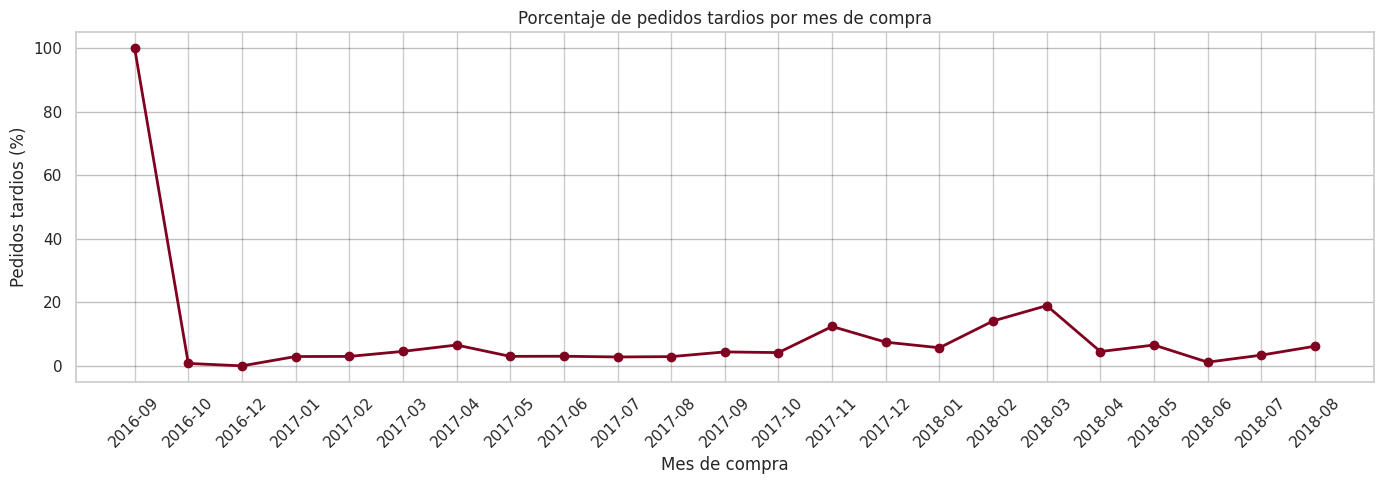

In [39]:
# Escribe aquí el código para desarrollar el análisis temporal, si aplica.
plt.figure(figsize=(14, 5))

plt.plot(
    resumen_mensual.index,
    resumen_mensual["porcentaje_tarde"],
    marker="o",
    color="#800020",
    linewidth=2
)

plt.title("Porcentaje de pedidos tardios por mes de compra")
plt.xlabel("Mes de compra")
plt.ylabel("Pedidos tardios (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", color="black", alpha=0.25)
plt.tight_layout()
plt.show()

## 6.2 Segmentación

1. **¿Qué grupos tendría sentido comparar?**

os pedidos que llegaron tarde y los que llegaron en la fecha estimada o antes.

---

2.**¿Qué criterio utilizarán para crear los segmentos?**
 diferencia_dias: si es mayor que 0, el pedido llego tarde; si es 0 o menor, llego en la fecha estimada o antes.

---

3.**¿Qué diferencias existen entre los grupos?**

Los pedidos tardios tardaron una mediana de 3,50 dias en llegar al transportador, frente a 2,15 dias en los demas. El tiempo de aprobacion fue parecido: 0,40 y 0,34 horas.

---

4.**¿Qué segmento presenta el comportamiento más particular?**
El de los pedidos tardios, porque tardaron mas en llegar al transportador.

---

5.**¿Qué decisión podría tomarse a partir de esas diferencias?**

Revisar cuanto tiempo pasa entre la compra y la entrega al transportador para ver si hay algo que se pueda mejorar.

---


**Criterio de segmentación seleccionado:**

Separe los pedidos segun si llegaron tarde (diferencia_dias > 0) o en la fecha estimada o antes (diferencia_dias <= 0).

In [40]:
# Escribe aquí el código para desarrollar la segmentación, si aplica.
df_segmentos = df_analisis.copy()

df_segmentos["resultado_entrega"] = np.where(
    df_segmentos["diferencia_dias"] > 0,
    "Tarde",
    "En fecha o antes"
)

df_segmentos["horas_hasta_aprobacion"] = (
    df_segmentos["order_approved_at"]
    - df_segmentos["order_purchase_timestamp"]
).dt.total_seconds() / 3600

df_segmentos["dias_hasta_transportador"] = (
    df_segmentos["order_delivered_carrier_date"]
    - df_segmentos["order_purchase_timestamp"]
).dt.total_seconds() / 86400

df_segmentos.loc[
    df_segmentos["dias_hasta_transportador"] < 0,
    "dias_hasta_transportador"
] = np.nan

resumen_segmentos = df_segmentos.groupby("resultado_entrega").agg(
    pedidos=("order_id", "count"),
    mediana_horas_aprobacion=("horas_hasta_aprobacion", "median"),
    mediana_dias_hasta_transportador=("dias_hasta_transportador", "median")
).round(2)

display(resumen_segmentos)

,pedidos,mediana_horas_aprobacion,mediana_dias_hasta_transportador
resultado_entrega,,,
En fecha o antes,89913,0.34,2.15
Tarde,6534,0.40,3.50


## 6.3 Análisis geográfico

1.**¿Qué variables permiten estudiar ubicaciones?**

En el archivo que elegi no hay variables de ubicacion solo aparece el identificador del cliente.

---
2.**¿Qué diferencias encuentran entre regiones?**
**

---

3.**¿La ubicación parece relacionarse con alguna variable de interés?**
**

---
4.**¿Qué limitaciones tiene la información geográfica?**
**

---
5.**¿Qué conclusiones no sería válido afirmar con estos datos?**
No seria valido decir que una region tiene mas retrasos o que la ubicacion influye en las entregas, porque no analice esos datos.

**Pregunta geográfica que desean investigar:**


In [41]:
# Escribe aquí el código para desarrollar el análisis geográfico, si aplica.
#no aplica

# Fase 7. Construcción de hallazgos

En esta fase deben dejar de pensar únicamente en funciones de Python y empezar a pensar como analistas.

Selecciona entre cinco y ocho hallazgos relevantes.

Para cada hallazgo responde:

1.**¿Qué encontraste?**


2.**¿Qué evidencia concreta respalda el hallazgo?**


3.**¿Qué variables y operaciones utilizaste?**


4.**¿Por qué es importante?**


5.**¿Qué explicación posible tiene?**

6.**¿Qué decisión podría tomar una organización con esta información?**


7.**¿Qué tan seguros están de su interpretación?**


**Hallazgo 1:**

la mayoria de los pedidos llego antes de la fecha estimada
- Que encontre: La mayoria llego antes, aunque algunos pedidos se retrasaron.
- Evidencia: De los 96.447 pedidos analizados, 88.621 llegaron antes, 1.292 en la fecha estimada y 6.534 despues. El 6,77 % llego tarde.
- Que revise: Compare la fecha real con la estimada y conte los resultados.
- Por que importa: Asi podemos ver si se estan cumpliendo las fechas prometidas.
- Que podria explicarlo: Tal vez las fechas estimadas se calculan con tiempo de sobra, pero no puedo confirmarlo con estos datos.
- Que se podria hacer: Seguir revisando los pedidos que llegan tarde.
- Que tan segura estoy: Estoy segura de los conteos, pero no se por que pasan los retrasos.

---


**Hallazgo 2:**
los retrasos cambian segun el mes
- Que encontre: El porcentaje de pedidos tarde fue distinto entre varios meses.
- Evidencia: En la parte de la tabla que revise, marzo de 2018 tuvo 18,96 % de pedidos tarde; febrero de 2018, 14,13 %; y noviembre de 2017, 12,40 %.
- Que revise: Agrupe los pedidos por mes de compra y calcule el porcentaje de retrasos.
- Por que importa: Ayuda a ver en que meses conviene revisar mejor las entregas.
- Que podria explicarlo: Quizas hubo mas compras o mas movimiento en esos meses, pero no lo comprobe.
- Que se podria hacer: Revisar esos meses y comparar cuantos pedidos hubo en cada uno.
- Que tan segura estoy: Los porcentajes salen de mis datos, pero no explican por que cambiaron.

---




**Hallazgos adicionales:**

los pedidos *tarde* tardaron mas en llegar al transportador
- Que encontre: Los pedidos tarde se demoraron mas en llegar al transportador que los pedidos que llegaron en fecha o antes.
- Evidencia: La demora tipica fue de 3,50 dias para los pedidos tarde y 2,15 para los otros. El tiempo de aprobacion fue casi igual: 0,40 y 0,34 horas.
- Que revise: Separe los pedidos por resultado de entrega y compare los tiempos.
- Por que importa: Puede ayudar a identificar una parte del proceso que conviene revisar.
- Que podria explicarlo: Algunos pedidos podrian tardar mas en prepararse o enviarse al transportador. No puedo asegurar que esa sea la causa.
- Que se podria hacer: Revisar cuanto tiempo pasa entre la compra y la entrega al transportador.
- Que tan segura estoy: Vi la diferencia en los datos, pero no puedo decir que una cosa cause la otra.

In [43]:
# Incluye aquí las tablas o visualizaciones finales que respalden tus hallazgos.
display(resumen_entregas)

display(
    resumen_mensual[["pedidos", "porcentaje_tarde"]]
)

display(
    resumen_segmentos[
        [
            "pedidos",
            "mediana_horas_aprobacion",
            "mediana_dias_hasta_transportador"
        ]
    ]
)

,pedidos,porcentaje
Antes de la fecha estimada,88621,91.89
En la fecha estimada,1292,1.34
Despues de la fecha estimada,6534,6.77


,pedidos,porcentaje_tarde
mes_compra,,
2016-09,1,100.00
2016-10,261,0.77
2016-12,1,0.00
2017-01,749,2.94
2017-02,1651,2.97
2017-03,2545,4.56
2017-04,2303,6.56
2017-05,3544,2.99
2017-06,3134,3.03


,pedidos,mediana_horas_aprobacion,mediana_dias_hasta_transportador
resultado_entrega,,,
En fecha o antes,89913,0.34,2.15
Tarde,6534,0.40,3.50


# Fase 8. Conclusiones y recomendaciones

## 8.1 Conclusiones

1.**¿Cuál era el problema o pregunta inicial?**

Queria saber si los pedidos llegaron antes o despues de la fecha que Olist habia calculado y si los retrasos cambiaban con el tiempo

---
2.**¿Qué lograron comprender a partir de los datos?**

En los pedidos que analicé, la mayoria llego antes de la fecha estimada: 91,89%. Un 6,77% llego tarde y un 1,34% llego justo ese dia.

---
3.**¿Qué hipótesis pudieron respaldar y cuáles no?**
Vimos que el porcentaje de pedidos tarde cambia segun el mes. El tiempo entre la compra y la aprobacion casi no se relaciono con el retraso. El tiempo hasta que el pedido se entrega al transportador **tuvo una relacion un poco mayor**, pero no alcanza para decir que esa sea la causa del retraso.

---

4.**¿Qué hallazgo consideran más importante?**

Que la mayoria de los pedidos llego antes de lo esperado, pero tambien hubo meses con mas pedidos tarde. Eso puede servir para revisar con mas cuidado esos periodos!

---


**Conclusión 1:**

La mayoria de los pedidos llego antes de la fecha estimada. En mis datos, 91,89% llego antes, 1,34% justo ese dia y 6,77% tarde

---
**Conclusión 2:**

Los retrasos no tuvieron el mismo porcentaje todos los meses. Esto muestra que vale la pena revisar los meses con mas pedidos tarde, teniendo en cuenta cuantos pedidos hubo en cada uno.

---
**Conclusión 3:**

El tiempo que pasa hasta entregar el pedido al transportador tuvo una relacion  con los retrasos. En cambio, el tiempo de aprobacion casi no mostro relacion. pero aun con esto estos datos no puedo asegurar que alguno de esos tiempos sea la causa.

## 8.2 Recomendaciones

Formula al menos tres recomendaciones dirigidas a una persona responsable de tomar decisiones.

Cada recomendación debe estar conectada con un hallazgo y explicar qué acción se propone y qué se espera mejorar.

**Recomendación 1:**

Revisar cada mes el porcentaje de pedidos tarde y tambien la cantidad de pedidos. Asi se pueden detectar meses que necesitan mas atencion sin sacar conclusiones por meses con muy pocos pedidos.

---

**Recomendación 2:**

Mirar con mas detalle los pedidos que tardan mas en llegar al transportador, porque en el analisis ese tiempo tuvo una relacion un poco mayor con los retrasos. Se podria revisar ese paso para encontrar donde se esta demorando el proceso.

---
**Recomendación 3:**

Revisar los casos con fechas muy distintas a lo normal antes de usarlos para tomar decisiones. En este archivo no aparece el motivo de cada caso, asi que convendria compararlos con informacion de transporte o servicio al cliente.